# Packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import re
import pyarrow
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import seaborn as sns
import scipy.stats as stats
import plotly.express as px
from datetime import date

# Read data

In [2]:
features_df = pd.read_parquet(r"..\data\features\features.parquet", engine="pyarrow")

In [3]:
# Mobile mean with a window of one hour
hours = 1
# Apply filters to the time series of the features
features_df = features_df[(features_df['energy']>=0)&(features_df['kurtosis']<2500)&(features_df['frequency_index']>=-3)&(features_df['entropy']>=0)&(features_df['entropy']<15000)]
# Calculate moving average for all features
# Apply logarithmic transformation to energy and kurtosis variables
features_df['energy_mobile_mean'] = np.log10(features_df['energy'].rolling(window=11*hours, center=False).mean())
features_df['kurtosis_mobile_mean'] = np.log10(features_df['kurtosis'].rolling(window=11*hours, center=False).mean())
features_df['frequency_index_mobile_mean'] = features_df['frequency_index'].rolling(window=11*hours, center=False).mean()
features_df['entropy_mobile_mean'] = features_df['entropy'].rolling(window=11*hours, center=False).mean()
features_df['energy'] = np.log10(features_df['energy'])
features_df['kurtosis'] = np.log10(features_df['kurtosis'])

### Training Set

In [4]:
# Select just one month of data
features_df_1_month = features_df[features_df['timestamp']<"2022-02-01"]
# Filter the first eleven observations with NAs values
features_df_1_month = features_df_1_month.dropna(subset=['energy_mobile_mean'])

In [5]:
# Take descriptive variables
variables = ["energy_mobile_mean",	"kurtosis_mobile_mean", "frequency_index_mobile_mean", "entropy_mobile_mean"]
X = features_df_1_month[["energy_mobile_mean",	"kurtosis_mobile_mean",	
                         "frequency_index_mobile_mean", "entropy_mobile_mean"]].to_numpy()


##### Preproccesing

In [6]:
# Scale variables
scaler = StandardScaler().fit(X)
X = scaler.transform(X)

Dimensionality Reduction:
PCA

In [7]:
# Create a PCA object and train it
pca = PCA(n_components=3).fit(X)
# Transform the data to the new reducted space
Z = pca.transform(X)

### Clustering

In [8]:
km_model = KMeans(n_clusters=3, random_state=9972, n_init=10).fit(Z)

In [13]:
# Create a dataframe with the clustering data
clustering_data = features_df_1_month[
    [   
        'timestamp',
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
].copy()
clustering_data['labels'] = km_model.labels_

### Groups Distribution

In [14]:
clustering_data[['labels', 'energy_mobile_mean']].groupby('labels').count()

,energy_mobile_mean
labels,
0,2775
1,4649
2,1459


### Results Original Data

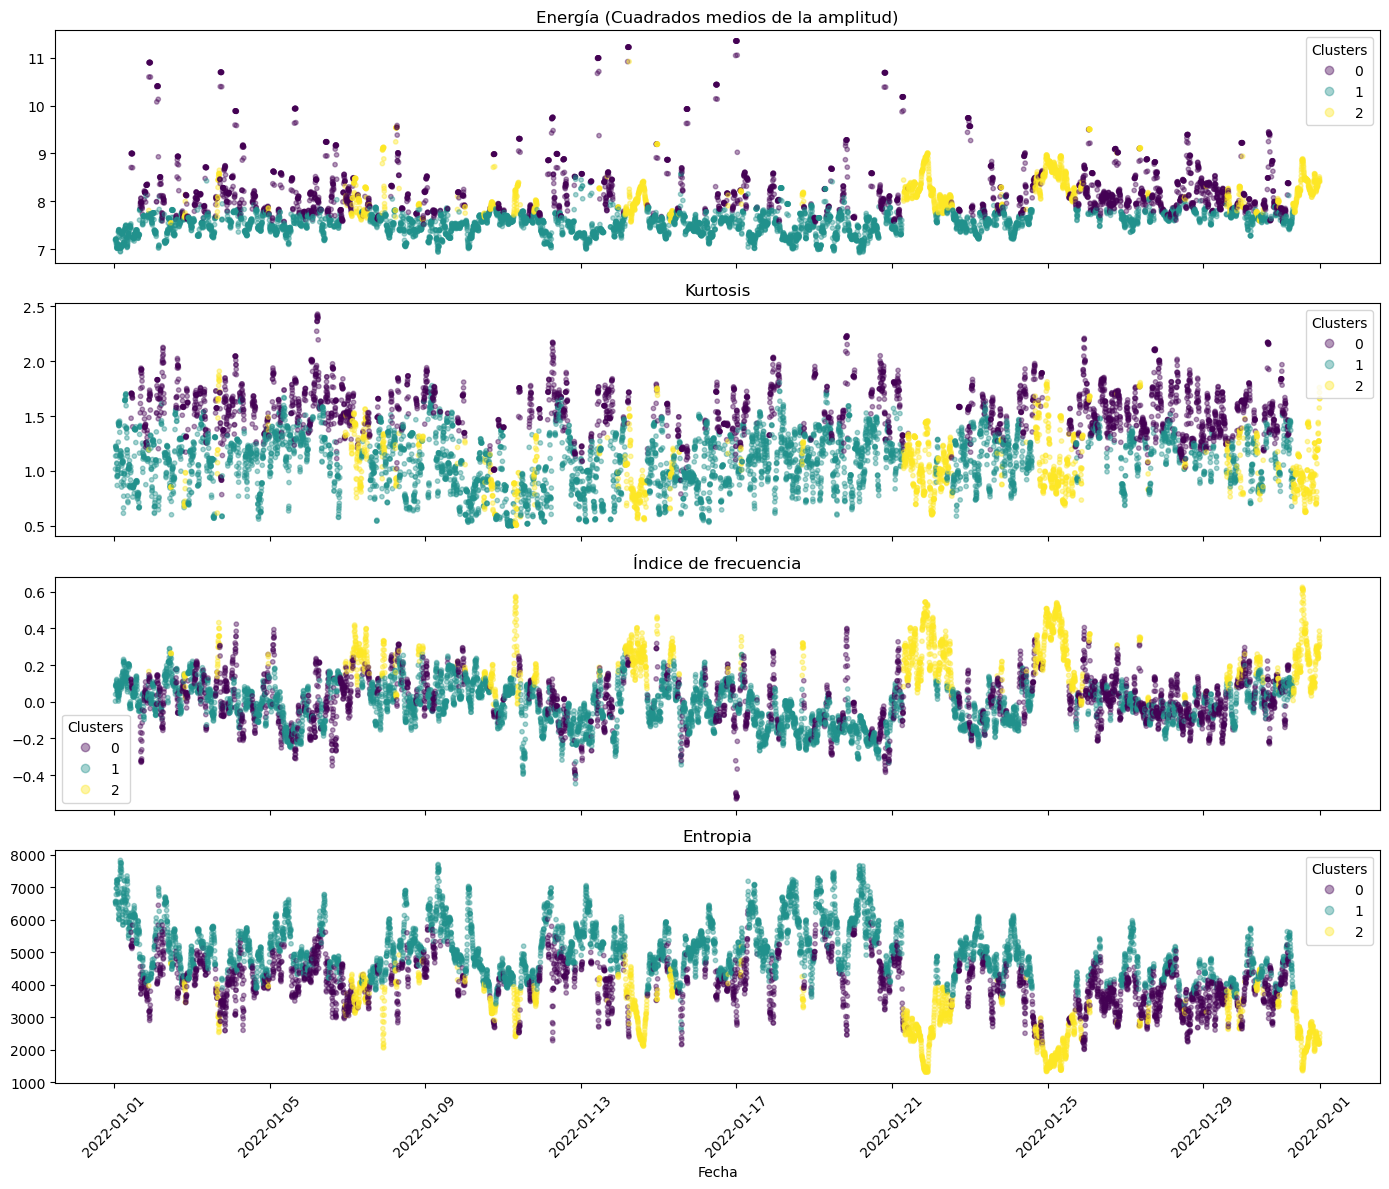

In [15]:
# Generate the plot
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
scatter = axes[0].scatter(clustering_data['timestamp'], clustering_data['energy_mobile_mean'], c=clustering_data['labels'], cmap='viridis', s=10, alpha=0.4)
axes[0].set_title('Energía (Cuadrados medios de la amplitud)')
axes[0].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[1].scatter(clustering_data['timestamp'], clustering_data['kurtosis_mobile_mean'], c=clustering_data['labels'], cmap='viridis', s=10, alpha=0.4)
axes[1].set_title('Kurtosis')
axes[1].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[2].scatter(clustering_data['timestamp'], clustering_data['frequency_index_mobile_mean'], c=clustering_data['labels'], cmap='viridis', s=10, alpha=0.4)
axes[2].set_title('Índice de frecuencia')
axes[2].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[3].scatter(clustering_data['timestamp'], clustering_data['entropy_mobile_mean'], c=clustering_data['labels'], cmap='viridis', s=10, alpha=0.4)
axes[3].set_title('Entropia')
axes[3].set_xlabel('Fecha')
axes[3].legend(*scatter.legend_elements(), title="Clusters")

plt.xticks(rotation=45)
plt.tight_layout()

### Identify Outliers

In [16]:
distances = km_model.transform(Z)
clustering_data['distance_to_centroid'] = [distances[i, label] for i, label in enumerate(km_model.labels_)]

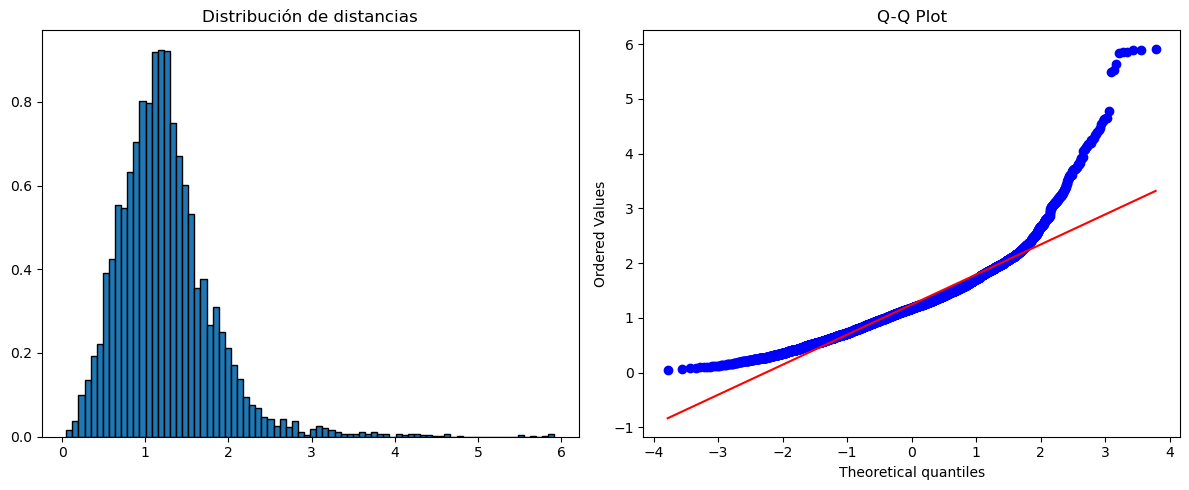

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
axes[0].hist(clustering_data['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')

# Q-Q plot
stats.probplot(clustering_data['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

In [18]:
# Clasificamos los valores observados como típicos y atípicos
clustering_data['outliers'] = clustering_data['distance_to_centroid'] > 5

In [19]:
# 
sum(clustering_data['outliers'])

9

### Next Months Forecast

In [20]:
features_df_pred = features_df[(features_df['timestamp']<"2025-01-01") & (features_df['timestamp']>="2022-02-01")]

clustering_data_pred = features_df_pred[
    [
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
]

In [21]:
# Scale variables
X_pred = scaler.transform(clustering_data_pred)
# Transform the data to the new reducted space
Z_pred = pca.transform(X_pred)

c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [22]:
# Predict clusters for new data using the same centroids
labels_pred = km_model.predict(Z_pred)

### Outliers in New Data

In [23]:
# Add labels and timestamp to the new dataframe
clustering_data_pred['timestamp'] = features_df_pred['timestamp']
clustering_data_pred['labels'] = labels_pred

distances_pred = km_model.transform(Z_pred)



clustering_data_pred['distance_to_centroid'] = [distances_pred[i, label] for i, label in enumerate(labels_pred)]
clustering_data_pred['outliers'] = clustering_data_pred['distance_to_centroid'] > 5


In [25]:
# Concat the test data
clustering_data_all = pd.concat([clustering_data, clustering_data_pred], axis = 0)

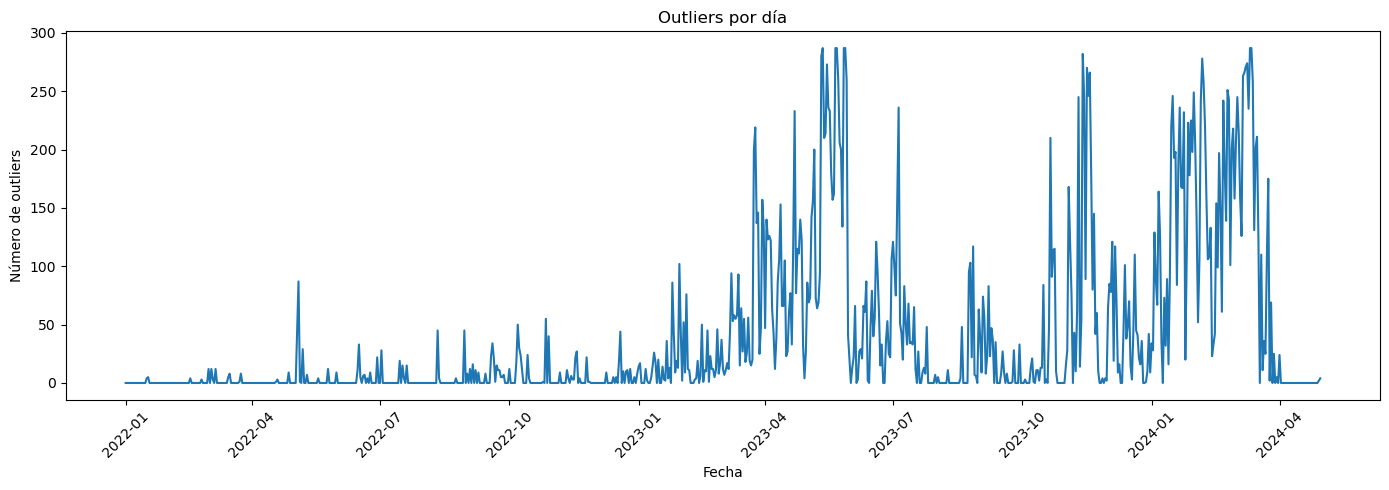

In [ ]:
clustering_data_all['date'] = pd.to_datetime(clustering_data_all['timestamp']).dt.date

total_by_day = buffer_pred.groupby('date').size()
outliers_by_day = (clustering_data_all[clustering_data_all['outliers'] == True]
                   .groupby('date')
                   .size())
# Reindex con todos los días, llenando con 0
outliers_by_day = outliers_by_day.reindex(total_by_day.index, fill_value=0)

outliers_by_day = outliers_by_day.reset_index()
outliers_by_day.columns = ['date', 'outliers']

plt.figure(figsize=(14, 5))
plt.plot(outliers_by_day['date'], outliers_by_day['outliers'])
plt.xlabel('Fecha')
plt.ylabel('Número de outliers')
plt.title('Outliers por día')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##Graficar el RSAM 
## Graficar valores de la segunda derivada (revisar puntos de inflexión)
## Primera derivada entre valores del día anterior o promedio de los últimos n días

In [ ]:
# outliers_by_day.to_csv(r'..\data\outliers\outliers_pred.csv', index = False)

### Model retraining

In [27]:
window_days = 84

outliers_by_day['mean_window'] = outliers_by_day['outliers'].rolling(window=window_days, center=False).mean()
outliers_by_day['std_window'] = outliers_by_day['outliers'].rolling(window=window_days, center=False).std()
outliers_by_day['threshold'] = outliers_by_day['mean_window'] + 3*outliers_by_day['std_window']
outliers_by_day['retrain'] = outliers_by_day['outliers'] > outliers_by_day['threshold']

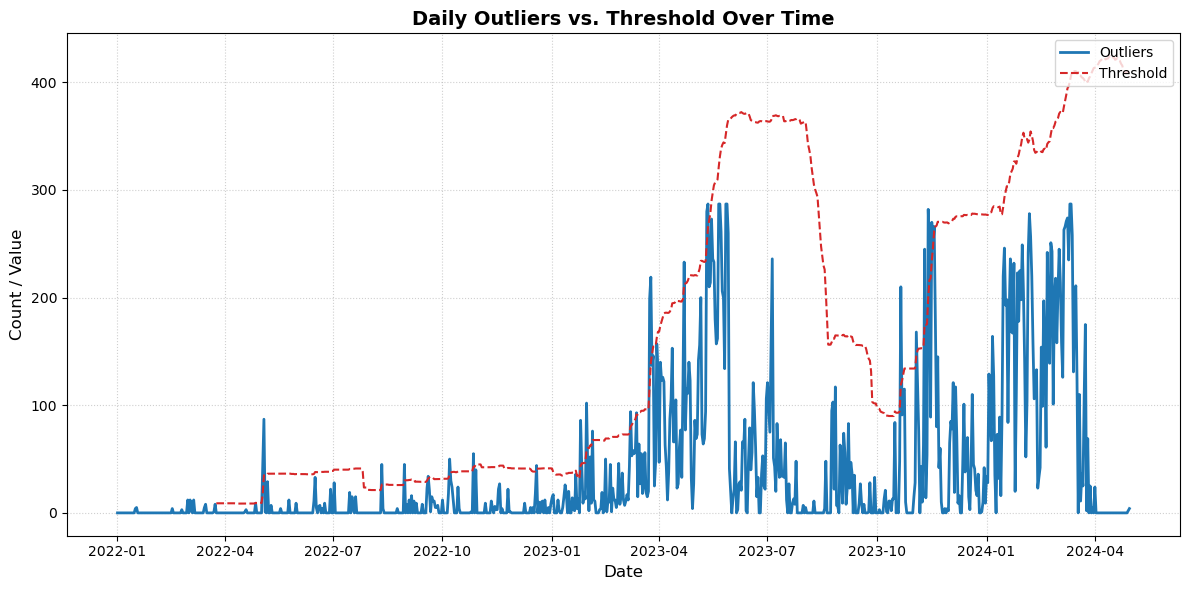

In [28]:
plt.figure(figsize=(12, 6))

# Plot the series
plt.plot(
    outliers_by_day['date'],
    outliers_by_day["outliers"],
    label="Outliers",
    color="#1f77b4",
    linewidth=2,
)
plt.plot(
    outliers_by_day['date'],
    outliers_by_day["threshold"],
    label="Threshold",
    color="#d62728",
    linestyle="--",
    linewidth=1.5,
)

# Formatting
plt.title("Daily Outliers vs. Threshold Over Time", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()

plt.show()

In [29]:
outliers_by_day[outliers_by_day['retrain'] == True]

,date,outliers,mean_window,std_window,threshold,retrain
121,2022-05-03,44,1.488095,5.445224,17.823766,True
122,2022-05-04,87,2.523810,10.799907,34.923529,True
221,2022-08-11,45,2.904762,7.802717,26.312912,True
240,2022-08-30,45,3.285714,8.975967,30.213616,True
260,2022-09-19,34,3.833333,9.415232,32.079028,True
278,2022-10-07,50,4.869048,10.382770,36.017359,True
298,2022-10-27,55,6.250000,12.237484,42.962453,True
348,2022-12-19,44,5.857143,11.782305,41.204059,True
385,2023-01-25,86,6.392857,12.451368,43.746962,True
390,2023-01-30,102,8.607143,16.625585,58.483897,True


#### Create new groups for the outliers before the cutday

In [33]:
buffer = clustering_data_all[(clustering_data_all['timestamp'] <= "2022-05-03") & clustering_data_all['outliers']].copy()[
    [
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
]

# Scale variables
X_buffer = scaler.transform(buffer)
# Transform the data to the new reducted space
Z_buffer = pca.transform(X_buffer)

print(f"Outliers en buffer: {len(buffer)}")

Outliers en buffer: 90


c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [34]:
# Trata con differentes valores para k
inertia = []
silh = []
k_s = np.arange(2, 10)
for k in k_s:
  km_model_aux = KMeans(n_clusters=k).fit(Z_buffer)
  inertia.append(km_model_aux.inertia_)
  silh.append(silhouette_score(Z_buffer, km_model_aux.labels_))

c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\javie\miniconda3\envs\estancia_popocatepetl

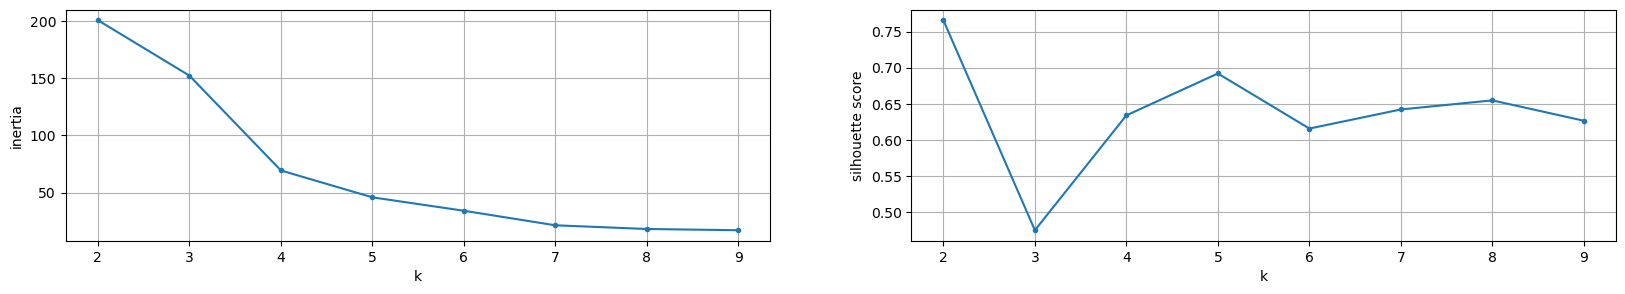

In [35]:
# Plot results
plt.figure(figsize=(20, 3))
plt.subplot(1, 2, 1)
plt.plot(k_s, inertia, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('inertia')
plt.subplot(1, 2, 2)
plt.plot(k_s, silh, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.show()

In [36]:
km_model_buffer = KMeans(n_clusters=5).fit(Z_buffer)

len(km_model_buffer.cluster_centers_)

c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


5

In [37]:
# Create a dataframe with the clustering data
clustering_data_buffer = pd.DataFrame(Z_buffer, columns= ['PC1', 'PC2', 'PC3'])
clustering_data_buffer['labels'] = km_model_buffer.labels_
# Create a dataframe with the clustering data


In [38]:
clustering_data_buffer[['labels','PC1']].groupby('labels').count()

,PC1
labels,
0,22
1,25
2,22
3,13
4,8


In [39]:
MIN_MIEMBROS = 20   # ajusta según lo que viste arriba

n_original = len(km_model.cluster_centers_)
promover = []   # índices del buffer que sí se promueven

for k in range(km_model_buffer.n_clusters):
    n = (km_model_buffer.labels_ == k).sum()
    if n >= MIN_MIEMBROS:
        promover.append(k)
        print(f"✓ Buffer {k} ({n} miembros) → será Cluster {n_original + len(promover) - 1}")
    else:
        print(f"✗ Buffer {k} ({n} miembros) → descartado, queda como anomalía")

✓ Buffer 0 (22 miembros) → será Cluster 3
✓ Buffer 1 (25 miembros) → será Cluster 4
✓ Buffer 2 (22 miembros) → será Cluster 5
✗ Buffer 3 (13 miembros) → descartado, queda como anomalía
✗ Buffer 4 (8 miembros) → descartado, queda como anomalía


In [40]:
mapping = {}   # {label_buffer: label_global}
for i, k in enumerate(promover):
    mapping[k] = n_original + i

print("Mapeo buffer → global:", mapping)

Mapeo buffer → global: {0: 3, 1: 4, 2: 5}


In [41]:
nuevos_centroides = km_model_buffer.cluster_centers_[promover]

centroides_expandidos = np.vstack([
    km_model.cluster_centers_,
    nuevos_centroides
])

print(f"Centroides: {n_original} → {len(centroides_expandidos)}")

Centroides: 3 → 6


In [42]:
buffer_labels_globales = np.array([
    mapping.get(lbl, -1) for lbl in km_model_buffer.labels_
])

buffer['labels_nuevo'] = buffer_labels_globales

print(pd.Series(buffer_labels_globales).value_counts().sort_index())

-1    21
 3    22
 4    25
 5    22
Name: count, dtype: int64


#### Changing the labels

In [43]:
past_data_df = clustering_data_all[(clustering_data_all['timestamp'] <= "2022-05-03")]

In [44]:
# Initialize with the original labels
past_data_df['labels_final'] = past_data_df['labels']

# Overwrite only the rows of the buffer using the index
past_data_df.loc[buffer.index, 'labels_final'] = buffer['labels_nuevo']

# Tag the points that still are outliers
past_data_df['outliers_final'] = past_data_df['labels_final'] == -1

In [45]:
past_data_df

,timestamp,energy_mobile_mean,kurtosis_mobile_mean,frequency_index_mobile_mean,entropy_mobile_mean,labels,distance_to_centroid,outliers,date,labels_final,outliers_final
10,2022-01-01 00:55:00,7.189824,1.016756,0.002807,6566.963119,1,1.206069,False,2022-01-01,1,False
11,2022-01-01 01:00:00,7.202035,1.135282,0.040282,6541.763823,1,1.238339,False,2022-01-01,1,False
12,2022-01-01 01:05:00,7.217582,1.225977,0.087732,6484.417105,1,1.376893,False,2022-01-01,1,False
13,2022-01-01 01:10:00,7.214921,1.221882,0.091360,6501.124913,1,1.392648,False,2022-01-01,1,False
14,2022-01-01 01:15:00,7.209869,1.217271,0.082832,6542.602102,1,1.389105,False,2022-01-01,1,False
...,...,...,...,...,...,...,...,...,...,...,...
35009,2022-05-02 23:35:00,7.873798,0.850295,0.160284,3420.510452,2,1.108501,False,2022-05-02,2,False
35010,2022-05-02 23:40:00,7.872155,0.846955,0.162567,3426.799153,2,1.110295,False,2022-05-02,2,False
35011,2022-05-02 23:45:00,7.860317,0.845550,0.166543,3474.404115,2,1.129949,False,2022-05-02,2,False
35012,2022-05-02 23:50:00,7.849372,0.843043,0.148777,3513.425641,2,1.215568,False,2022-05-02,2,False


In [47]:
n_before = past_data_df['outliers'].sum()
n_after = past_data_df['outliers_final'].sum()

print(f"Outliers antes:   {n_before}")
print(f"Outliers después: {n_after}")
print(f"Absorbidos:       {n_before - n_after}\n")

print(past_data_df['labels_final'].value_counts().sort_index())

Outliers antes:   90
Outliers después: 21
Absorbidos:       69

labels_final
-1       21
 0    11083
 1    11930
 2    10739
 3       22
 4       25
 5       22
Name: count, dtype: int64


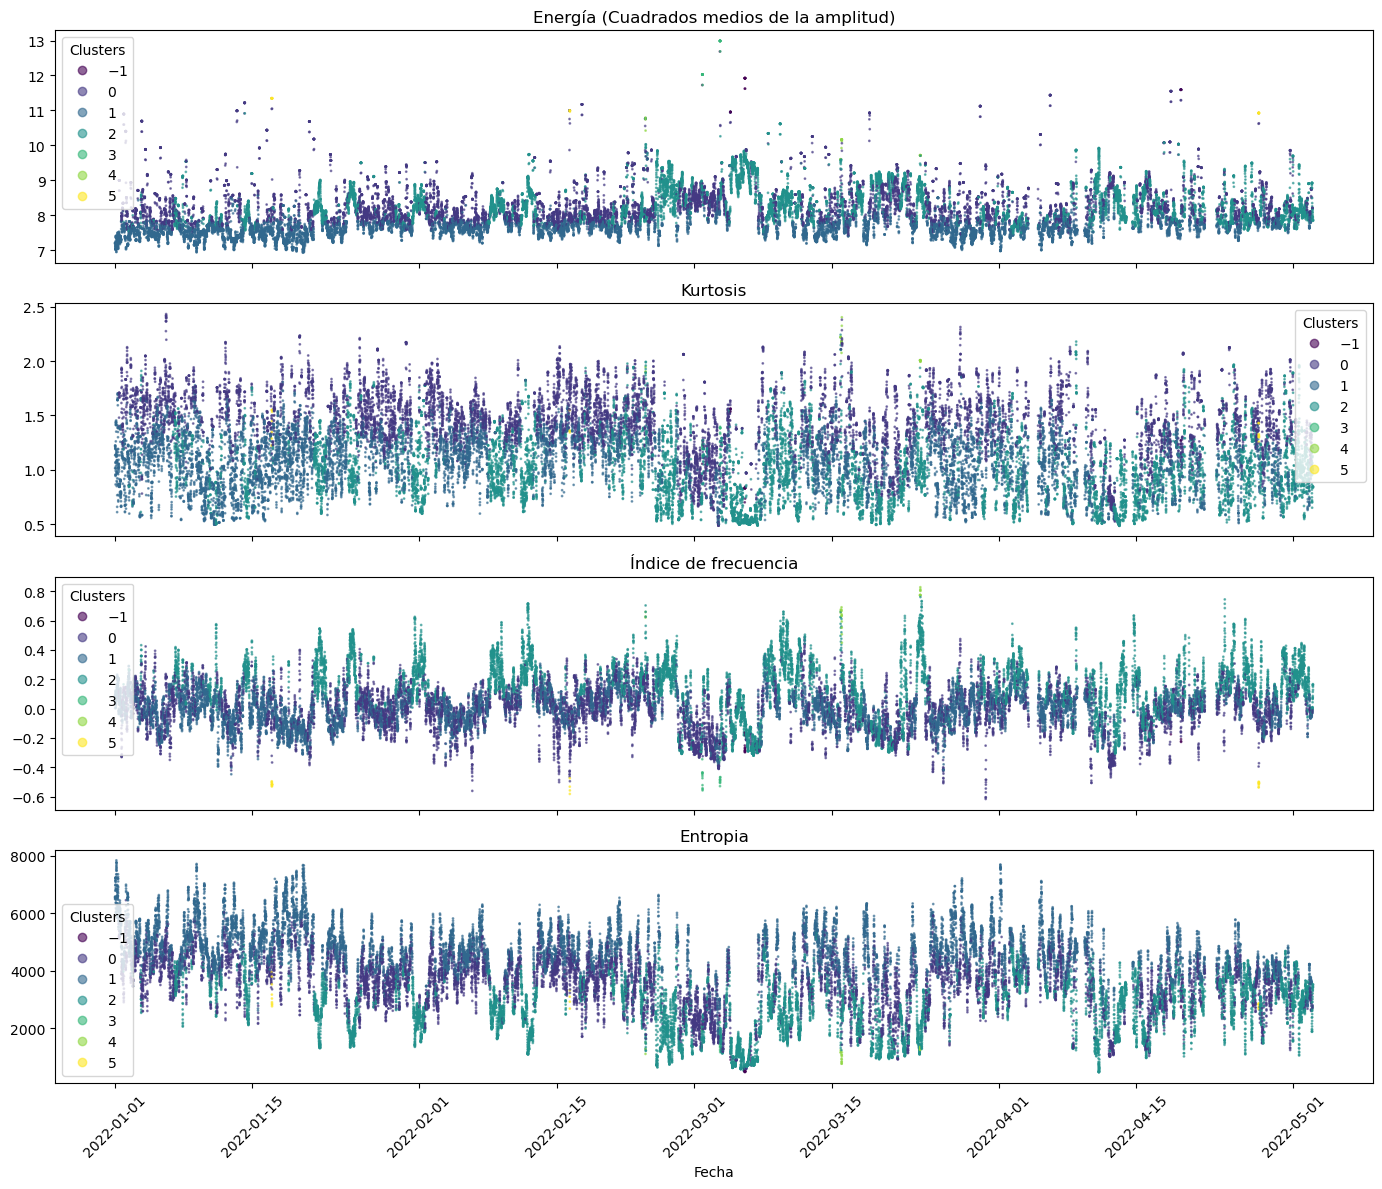

In [48]:
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
scatter = axes[0].scatter(past_data_df['timestamp'], past_data_df['energy_mobile_mean'], c=past_data_df['labels_final'], cmap='viridis', s=1, alpha=0.6)
axes[0].set_title('Energía (Cuadrados medios de la amplitud)')
axes[0].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[1].scatter(past_data_df['timestamp'], past_data_df['kurtosis_mobile_mean'], c=past_data_df['labels_final'], cmap='viridis', s=1, alpha=0.6)
axes[1].set_title('Kurtosis')
axes[1].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[2].scatter(past_data_df['timestamp'], past_data_df['frequency_index_mobile_mean'], c=past_data_df['labels_final'], cmap='viridis', s=1, alpha=0.6)
axes[2].set_title('Índice de frecuencia')
axes[2].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[3].scatter(past_data_df['timestamp'], past_data_df['entropy_mobile_mean'], c=past_data_df['labels_final'], cmap='viridis', s=1, alpha=0.6)
axes[3].set_title('Entropia')
axes[3].set_xlabel('Fecha')
axes[3].legend(*scatter.legend_elements(), title="Clusters")



plt.xticks(rotation=45)
plt.tight_layout()

#### Retrain only for outliers

In [66]:
buffer_pred = clustering_data_all[(clustering_data_all['timestamp'] > "2022-05-03") & clustering_data_all['outliers']].copy()[
    [   
        'timestamp',
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
]



# Scale variables
X_buffer_pred = buffer_pred [
    [   
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
].to_numpy()

X_buffer_pred = scaler.transform(X_buffer_pred)
# Transform the data to the new reducted space
Z_buffer_pred = pca.transform(X_buffer_pred)

print(f"Outliers nuevos: {len(buffer_pred)}")

Outliers nuevos: 33405


In [67]:
labels_outliers_pred = km_model_buffer.predict(Z_buffer_pred)
distances_outliers_pred = km_model_buffer.transform(Z_buffer_pred)
buffer_pred['distance_to_centroid'] = [distances_outliers_pred[i, label] for i, label in enumerate(labels_outliers_pred)]


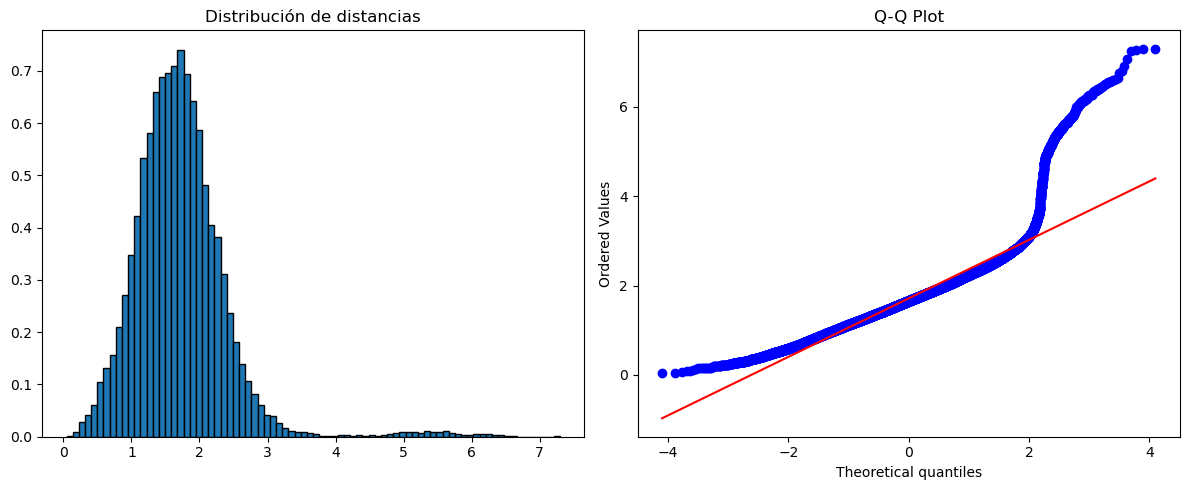

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
axes[0].hist(buffer_pred['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')

# Q-Q plot
stats.probplot(buffer_pred['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

In [69]:
buffer_pred['outliers'] = buffer_pred['distance_to_centroid'] > 5
sum(buffer_pred['outliers'])

345

In [70]:
buffer_pred['date'] = pd.to_datetime(buffer_pred['timestamp']).dt.date

total_by_day = buffer_pred.groupby('date').size()
outliers_by_day = (buffer_pred[buffer_pred['outliers'] == True]
                   .groupby('date')
                   .size())
# Reindex con todos los días, llenando con 0
outliers_by_day = outliers_by_day.reindex(total_by_day.index, fill_value=0)

outliers_by_day = outliers_by_day.reset_index()
outliers_by_day.columns = ['date', 'outliers']

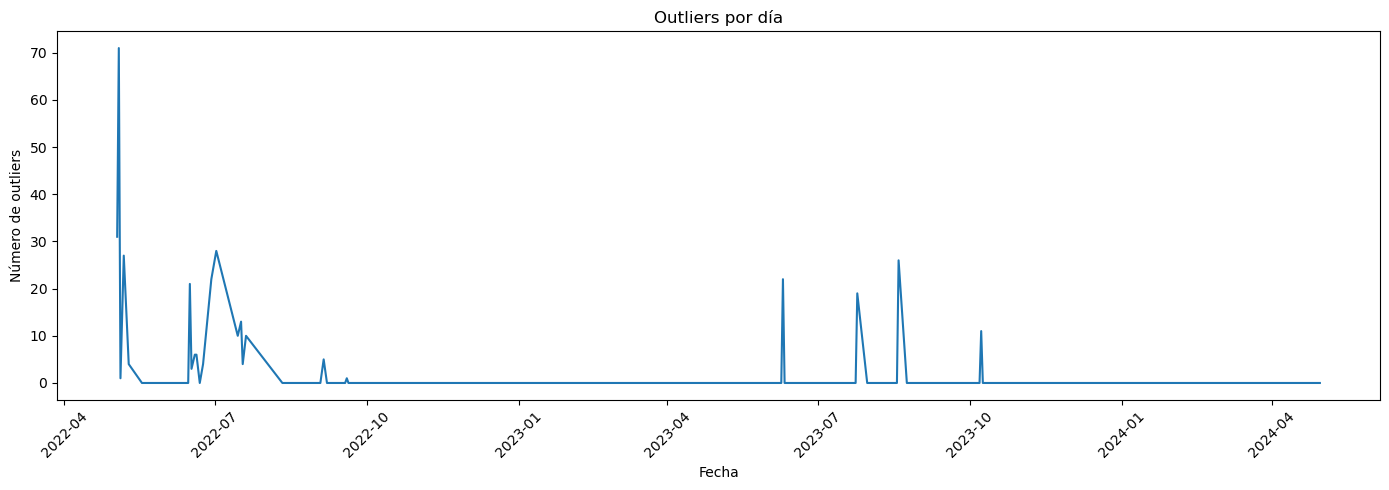

In [71]:
plt.figure(figsize=(14, 5))
plt.plot(outliers_by_day['date'], outliers_by_day['outliers'])
plt.xlabel('Fecha')
plt.ylabel('Número de outliers')
plt.title('Outliers por día')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [73]:
outliers_by_day.head(30)

,date,outliers
0,2022-05-03,31
1,2022-05-04,71
2,2022-05-05,1
3,2022-05-07,27
4,2022-05-10,4
5,2022-05-18,0
6,2022-05-25,0
7,2022-05-31,0
8,2022-06-15,0
9,2022-06-16,21
